In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rc("font", family="AppleGothic")

deathrates = pd.read_csv("deathrates.csv", encoding="utf-8")
pop = pd.read_csv("popcities10.csv", encoding="utf-8")

### 1-1


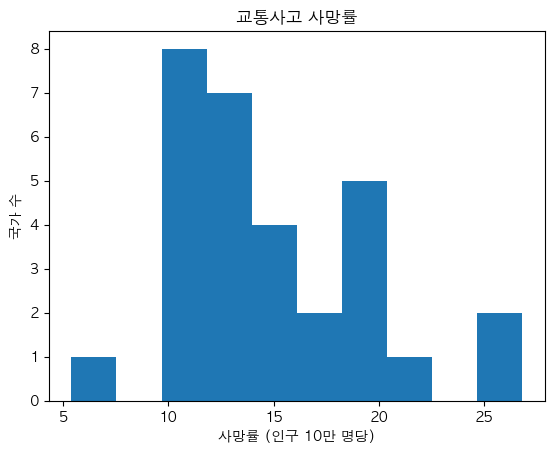

In [2]:
plt.hist(deathrates["death"])
plt.title("교통사고 사망률")
plt.xlabel("사망률 (인구 10만 명당)")
plt.ylabel("국가 수")
plt.show()

### 1-2


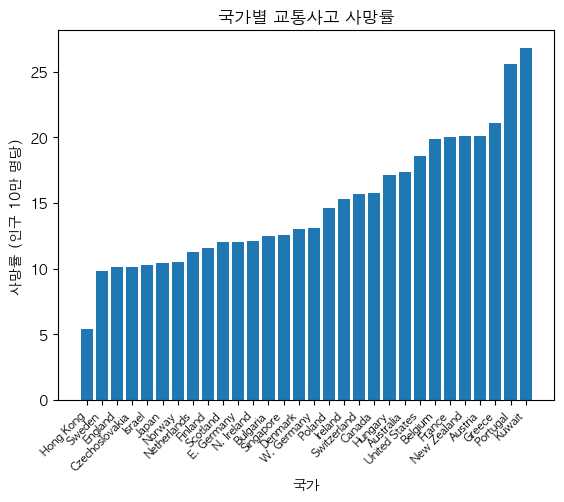

In [3]:
deathrates = deathrates.sort_values("death")

plt.bar(deathrates["country"], deathrates["death"])
plt.title("국가별 교통사고 사망률")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.xlabel("국가")
plt.ylabel("사망률 (인구 10만 명당)")
plt.show()

### 1-3


In [4]:
deathrates["grade"] = pd.cut(
    deathrates["death"],
    bins=[0, 10, 20, 30],
    labels=["Low", "Medium", "High"],
)
deathrates.head()

,country,death,grade
14,Hong Kong,5.4,Low
28,Sweden,9.8,Low
29,England,10.1,Medium
1,Czechoslovakia,10.1,Medium
3,Israel,10.3,Medium


### 1-4


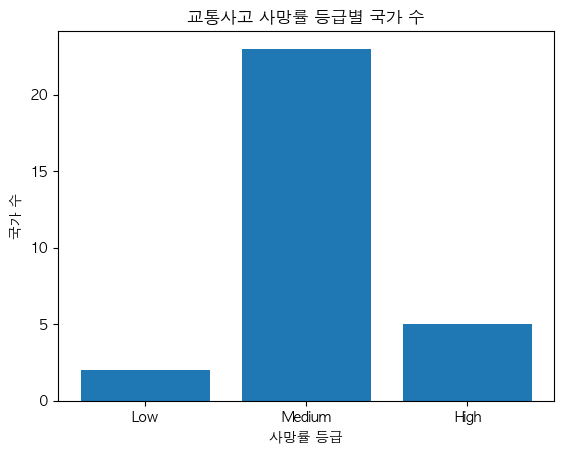

In [5]:
grade = deathrates["grade"].value_counts().sort_index()

plt.bar(grade.index.astype(str).tolist(), grade.tolist())
plt.title("교통사고 사망률 등급별 국가 수")
plt.xlabel("사망률 등급")
plt.ylabel("국가 수")
plt.show()

### 2-1


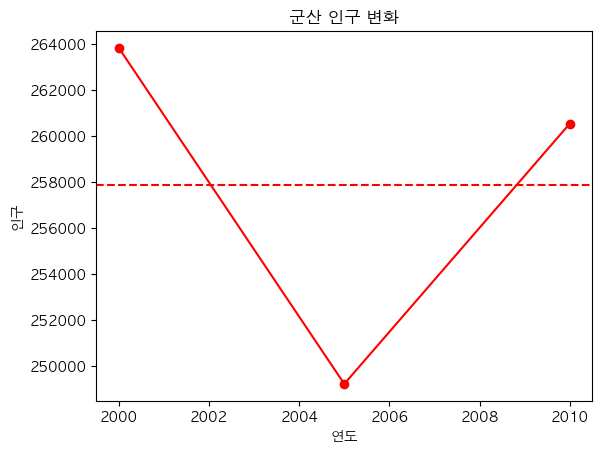

In [6]:
years = [2000, 2005, 2010]
gunsan = pop.loc[pop["municipality"] == "Gunsan", ["pop00", "pop05", "pop10"]]
gunsan = gunsan.iloc[0]

plt.plot(years, gunsan, marker="o", color="r")
plt.axhline(gunsan.mean(), linestyle="--", color="r")
plt.title("군산 인구 변화")
plt.xlabel("연도")
plt.ylabel("인구")
plt.show()

### 2-2


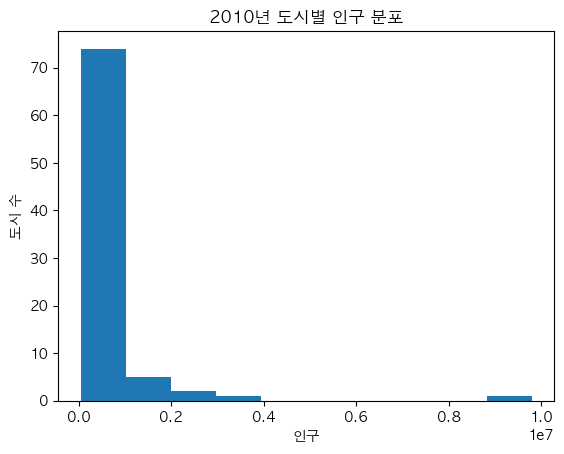

In [7]:
plt.hist(pop["pop10"])
plt.title("2010년 도시별 인구 분포")
plt.xlabel("인구")
plt.ylabel("도시 수")
plt.show()

### 2-3


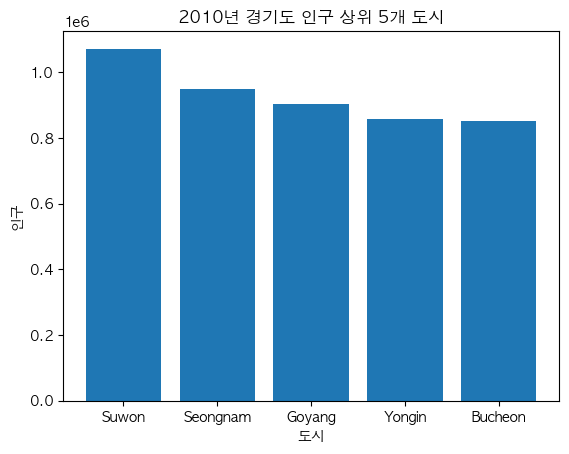

In [8]:
gyeonggi_top5 = pop[pop["provinces"] == "Gyeonggi"].nlargest(5, "pop10")

plt.bar(gyeonggi_top5["municipality"], gyeonggi_top5["pop10"])
plt.title("2010년 경기도 인구 상위 5개 도시")
plt.xlabel("도시")
plt.ylabel("인구")
plt.show()

### 2-4


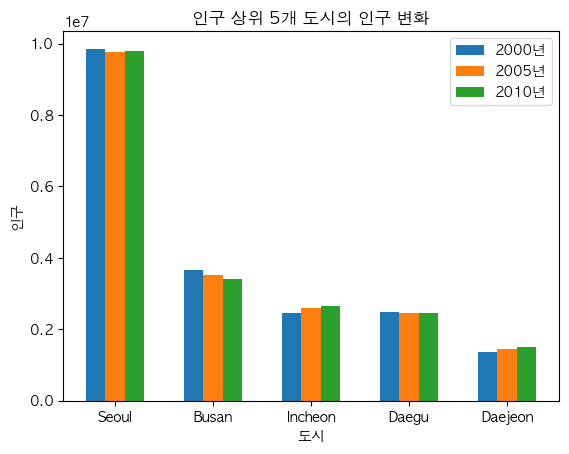

In [9]:
top5 = pop.nlargest(5, "pop10")
x = np.arange(len(top5))
width = 0.2

plt.bar(x - width, top5["pop00"], width, label="2000년")
plt.bar(x, top5["pop05"], width, label="2005년")
plt.bar(x + width, top5["pop10"], width, label="2010년")
plt.xticks(x, top5["municipality"].tolist())
plt.title("인구 상위 5개 도시의 인구 변화")
plt.xlabel("도시")
plt.ylabel("인구")
plt.legend()
plt.show()

### 2-5


In [10]:
pop["growth"] = (pop["pop10"] - pop["pop00"]) / pop["pop00"] * 100
growth_top7 = pop.nlargest(7, "growth")
growth_top7[["municipality", "growth"]]

,municipality,growth
21,Hwaseong,162.802790
11,Yongin,122.686171
29,Paju,85.249085
43,Gwangju,83.307022
50,Osan,79.778466
48,Yangju,74.898548
18,Namyangju,56.061200


### 2-6


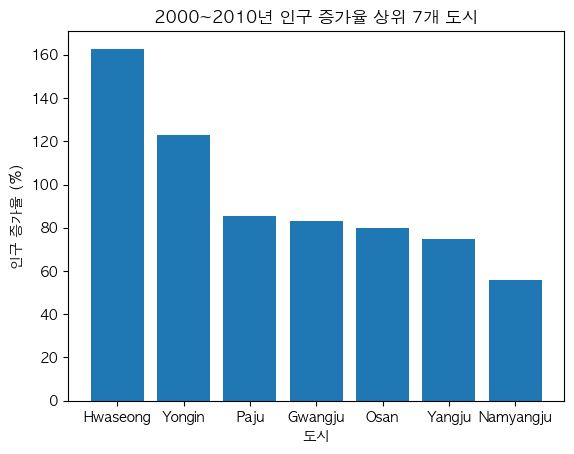

In [11]:
plt.bar(growth_top7["municipality"], growth_top7["growth"])
plt.title("2000~2010년 인구 증가율 상위 7개 도시")
plt.xlabel("도시")
plt.ylabel("인구 증가율 (%)")
plt.show()